In [12]:
import pandas as pd

## Pandas DataFrame

In [42]:
df = pd.read_csv("/Users/omikapatel/Desktop/Python_Decal/course_assignments/homework8/state_data.csv")
print(df)

   state   latitude   longitude                  name
0     AK  63.588753 -154.493062                Alaska
1     AL  32.318231  -86.902298               Alabama
2     AR  35.201050  -91.831833              Arkansas
3     AZ  34.048928 -111.093731               Arizona
4     CA  36.778261 -119.417932            California
5     CO  39.550051 -105.782067              Colorado
6     CT  41.603221  -73.087749           Connecticut
7     DC  38.905985  -77.033418  District of Columbia
8     DE  38.910832  -75.527670              Delaware
9     FL  27.664827  -81.515754               Florida
10    GA  32.157435  -82.907123               Georgia
11    HI  19.898682 -155.665857                Hawaii
12    IA  41.878003  -93.097702                  Iowa
13    ID  44.068202 -114.742041                 Idaho
14    IL  40.633125  -89.398528              Illinois
15    IN  40.551217  -85.602364               Indiana
16    KS  39.011902  -98.484246                Kansas
17    KY  37.839333  -84.270

In [5]:
print(df.shape) # 52 rows, 4 columns

(52, 4)


In [11]:
print(df.head())
print(df.tail())
# the first state is alabama and the last is wyoming
# there are 52 entries
# Peurto Rico and the District of Columbia are listed among the 50 states, making it 52 total entries

  state   latitude   longitude        name
0    AK  63.588753 -154.493062      Alaska
1    AL  32.318231  -86.902298     Alabama
2    AR  35.201050  -91.831833    Arkansas
3    AZ  34.048928 -111.093731     Arizona
4    CA  36.778261 -119.417932  California
   state   latitude   longitude           name
47    VT  44.558803  -72.577841        Vermont
48    WA  47.751074 -120.740139     Washington
49    WI  43.784440  -88.787868      Wisconsin
50    WV  38.597626  -80.454903  West Virginia
51    WY  43.075968 -107.290284        Wyoming


In [43]:
median_lat = df["latitude"].median()
median_long = df["longitude"].median()
print("median latitude", median_lat)
print("median longitude", median_long)

median latitude 39.4355155
median longitude -89.093198


In [44]:
df["lat_distance"] = (df["latitude"] - median_lat).abs()
# print(df["lat_distance"])
df["long_distance"] = (df["longitude"] - median_long).abs()
# print(df["long_distance"])
print(df)

   state   latitude   longitude                  name  lat_distance  \
0     AK  63.588753 -154.493062                Alaska     24.153237   
1     AL  32.318231  -86.902298               Alabama      7.117285   
2     AR  35.201050  -91.831833              Arkansas      4.234465   
3     AZ  34.048928 -111.093731               Arizona      5.386588   
4     CA  36.778261 -119.417932            California      2.657255   
5     CO  39.550051 -105.782067              Colorado      0.114536   
6     CT  41.603221  -73.087749           Connecticut      2.167705   
7     DC  38.905985  -77.033418  District of Columbia      0.529530   
8     DE  38.910832  -75.527670              Delaware      0.524684   
9     FL  27.664827  -81.515754               Florida     11.770689   
10    GA  32.157435  -82.907123               Georgia      7.278081   
11    HI  19.898682 -155.665857                Hawaii     19.536834   
12    IA  41.878003  -93.097702                  Iowa      2.442487   
13    

In [45]:
print(df.shape) # 52 rows, 6 columns

(52, 6)


In [55]:
# for median latitude
closest_latidx = df["lat_distance"].idxmin()
farthest_latidx = df["lat_distance"].idxmax()

closest_latstate = df.loc[closest_latidx, "state"]
closest_latamt = df.loc[closest_latidx, "lat_distance"]

farthest_latstate = df.loc[farthest_latidx, "state"]
farthest_latamt = df.loc[farthest_latidx, "long_distance"]

print(f"state closest to median latitude: {closest_latstate}, {closest_latamt:.2f}")
print(f"state farthest to median latitude: {farthest_latstate}, {farthest_latamt:.2f}")

# for median longitude
closest_longidx = df["long_distance"].idxmin()
farthest_longidx = df["long_distance"].idxmax()

closest_longstate = df.loc[closest_longidx, "state"]
closest_longamt = df.loc[closest_longidx, "long_distance"]

farthest_longstate = df.loc[farthest_longidx, "state"]
farthest_longamt = df.loc[farthest_longidx, "long_distance"]

print(f"state closest to median longitude: {closest_longstate}, {closest_longamt:.2f}")
print(f"state farthest to median longitude: {farthest_longstate}, {farthest_longamt:.2f}")

state closest to median latitude: CO, 0.11
state farthest to median latitude: AK, 65.40
state closest to median longitude: IL, 0.31
state farthest to median longitude: HI, 66.57


In [58]:
for row in df.itertuples():
    print(row)
    break # did this so it wouldnt blow up my laptop
# this returns each row as a tuple. i just found it in the indexing and iteration section. it's useful for when you want to view your data as groups like shown by the function rather than an entire table. may be easier to read than a table at some times.

Pandas(Index=0, state='AK', latitude=63.588753, longitude=-154.493062, name='Alaska', lat_distance=24.153237499999996, long_distance=65.39986400000001)


## Seaborn

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = sns.load_dataset("iris")
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [21]:
df = df.dropna(axis=1)

print(df.shape) # 150 rows, 5 columns
print(df.head())
print(df.tail())

# the columns, named below, represent the length, width, and species of the flowers for this sepals and petals

(150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica


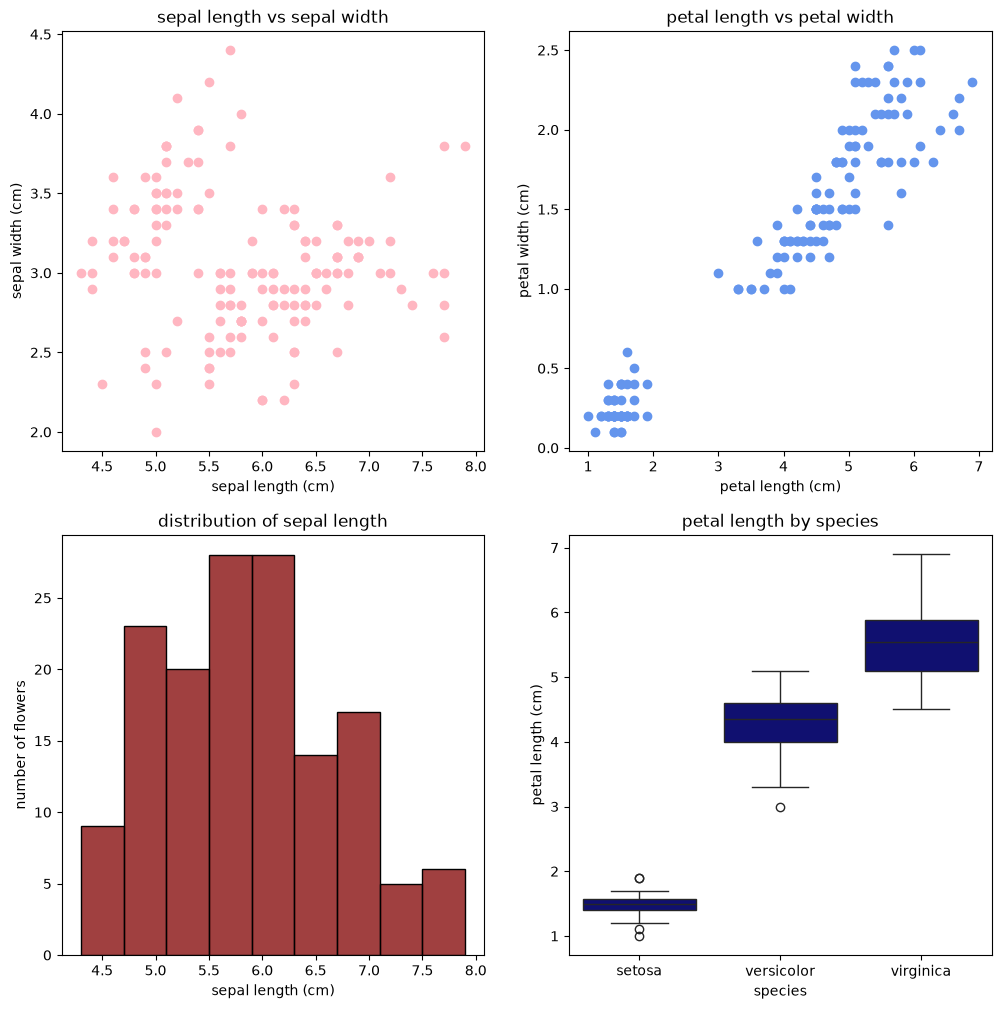

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(12,12))

ax[0,0].scatter(df["sepal_length"], df["sepal_width"], color = "lightpink")
ax[0,0].set_title("sepal length vs sepal width")
ax[0,0].set_xlabel("sepal length (cm)")
ax[0,0].set_ylabel("sepal width (cm)")

ax[0,1].scatter(df["petal_length"], df["petal_width"], color = "cornflowerblue")
ax[0,1].set_title("petal length vs petal width")
ax[0,1].set_xlabel("petal length (cm)")
ax[0,1].set_ylabel("petal width (cm)")

sns.histplot(data=df, x="sepal_length", color = "maroon", ax=ax[1,0])
ax[1,0].set_title("distribution of sepal length")
ax[1,0].set_xlabel("sepal length (cm)")
ax[1,0].set_ylabel("number of flowers")

sns.boxplot(data=df, x="species", y="petal_length", color = "navy", ax=ax[1,1])
ax[1,1].set_title("petal length by species")
ax[1,1].set_xlabel("species")
ax[1,1].set_ylabel("petal length (cm)")

plt.show()

In [ ]:
# top left: shows how the length and width relate to each other; there is no clear relationship with them
# top right: shows the relationship with the petal length and width; appears to have a strong positive correlation
# bottom left: shows how many flowers fall into each range of sepal length; most cluster between 5-6cm
# bottom right: compares petal length for the species; setosa has very short ones, while the other two overlap slightly, and they have longer petals